# **Analisis Pola dan Prediksi Penjualan Berbasis Data Time Series Menggunakan Metode ARIMA**

Kelompok 7:

1. Nadine Putri Aulia (24031554094)
2. Putri Sofiyatus Salwa (24031554112)
3. Cintiya Agustin Nareswari (24031554218)

# **Link Dataset:**
https://www.kaggle.com/datasets/hamza0027/global-retail-sales-dataset

# **Pipeline Penelitian**

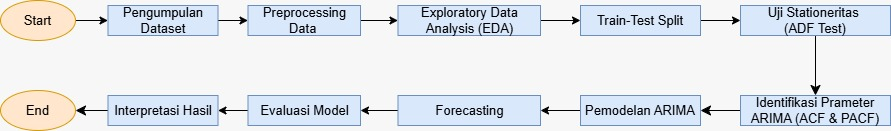

## **Import Library**

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from google.colab import drive
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.metrics import(
mean_absolute_error,
mean_squared_error,
mean_absolute_percentage_error, r2_score
)

warnings.filterwarnings("ignore")

## **Load Data**

In [69]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [70]:
data=pd.read_csv("/content/drive/Shareddrives/project mining_kelompok 7/real_world_sales_dataset_5000.csv")

In [71]:
data.columns=data.columns.str.lower()

In [72]:
data.head()

,order_id,order_date,customer_name,city,country,sales_channel,product_category,product_name,quantity,unit_price,discount_percent,revenue,cost,profit,payment_method,customer_rating
0,ORD-100001,2024-01-24,Benjamin Mcclure,Chicago,USA,Mobile App,Electronics,Tablet,7,681.05,0.21,3766.21,3158.69,607.52,Cash on Delivery,3
1,ORD-100002,2023-01-02,Sherry Barnes,Berlin,Germany,Retail Store,Home & Living,Sofa,3,856.30,0.08,2363.39,1491.07,872.32,Credit Card,5
2,ORD-100003,2024-11-14,Kenneth Mccoy,New York,USA,Online,Beauty,Perfume,6,1835.46,0.03,10682.38,6030.02,4652.36,Debit Card,1
3,ORD-100004,2023-12-18,Carol Dudley,Istanbul,Turkey,Mobile App,Home & Living,Curtains,8,678.00,0.21,4284.96,3443.83,841.13,Bank Transfer,2
4,ORD-100005,2024-03-20,Ann Skinner,Istanbul,Turkey,Mobile App,Sports,Tennis Racket,6,51.12,0.22,239.24,182.60,56.64,Cash on Delivery,5


In [73]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   object 
 1   order_date        5000 non-null   object 
 2   customer_name     5000 non-null   object 
 3   city              5000 non-null   object 
 4   country           5000 non-null   object 
 5   sales_channel     5000 non-null   object 
 6   product_category  5000 non-null   object 
 7   product_name      5000 non-null   object 
 8   quantity          5000 non-null   int64  
 9   unit_price        5000 non-null   float64
 10  discount_percent  5000 non-null   float64
 11  revenue           5000 non-null   float64
 12  cost              5000 non-null   float64
 13  profit            5000 non-null   float64
 14  payment_method    5000 non-null   object 
 15  customer_rating   5000 non-null   int64  
dtypes: float64(5), int64(2), object(9)
memory 

In [74]:
data.describe()

,quantity,unit_price,discount_percent,revenue,cost,profit,customer_rating
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,4.477200,1271.526618,0.125580,4996.396474,3567.456580,1428.939894,3.017000
std,2.285897,726.063341,0.072414,4144.685425,3032.480458,1330.136061,1.412908
min,1.000000,20.050000,0.000000,27.010000,15.690000,3.360000,1.000000
25%,3.000000,629.765000,0.060000,1590.635000,1136.422500,409.635000,2.000000
50%,4.000000,1258.050000,0.130000,3871.680000,2737.605000,1010.975000,3.000000
75%,6.000000,1924.217500,0.190000,7418.277500,5276.427500,2053.127500,4.000000
max,8.000000,2499.790000,0.250000,19708.480000,16055.870000,8244.340000,5.000000


In [75]:
print("Missing Value")
data.isnull().sum()

Missing Value


,0
order_id,0
order_date,0
customer_name,0
city,0
country,0
sales_channel,0
product_category,0
product_name,0
quantity,0
unit_price,0


In [76]:
print("\nDuplicate")
data.duplicated().sum()


Duplicate


np.int64(0)

## **Preprocessing**

In [77]:
data['order_date']=pd.to_datetime(data['order_date'])
data=data.sort_values('order_date')

## **Agregasi Mingguan**

In [78]:
weekly=data.resample(
'W',
on='order_date'
)['revenue'].sum().reset_index()

print("Data Mingguan")
print(weekly.head())

print("\nJumlah Data:")
print(len(weekly))

print("\nStatistik")
weekly['revenue'].describe()

Data Mingguan
  order_date    revenue
0 2023-01-01   33302.39
1 2023-01-08  221710.44
2 2023-01-15  168424.52
3 2023-01-22  237224.22
4 2023-01-29  225833.47

Jumlah Data:
130

Statistik


,revenue
count,130.000000
mean,192169.095154
std,43386.980313
min,33302.390000
25%,168425.855000
50%,193759.630000
75%,220851.802500
max,290729.850000


In [79]:
Q1=weekly['revenue'].quantile(.25)
Q3=weekly['revenue'].quantile(.75)

IQR=Q3-Q1

lower=Q1-(1.5*IQR)
upper=Q3+(1.5*IQR)

outlier=weekly[
(weekly['revenue']<lower)|
(weekly['revenue']>upper)
]

print("\nJumlah Outlier:")
print(len(outlier))

outlier.head()


Jumlah Outlier:
2


,order_date,revenue
0,2023-01-01,33302.39
129,2025-06-22,76854.94


## **Visualisasi EDA**

In [80]:
print("Tanggal Awal")
print(data['order_date'].min())

print("\nTanggal Akhir")
print(data['order_date'].max())

Tanggal Awal
2023-01-01 00:00:00

Tanggal Akhir
2025-06-19 00:00:00


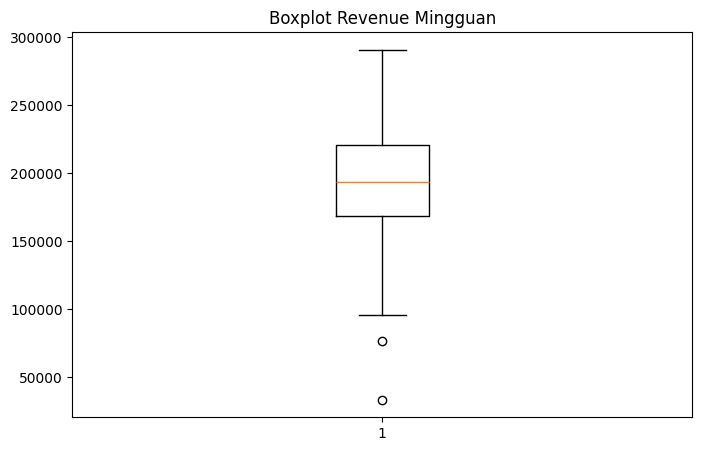

In [81]:
plt.figure(figsize=(8,5))
plt.boxplot(weekly['revenue'])
plt.title("Boxplot Revenue Mingguan")
plt.show()

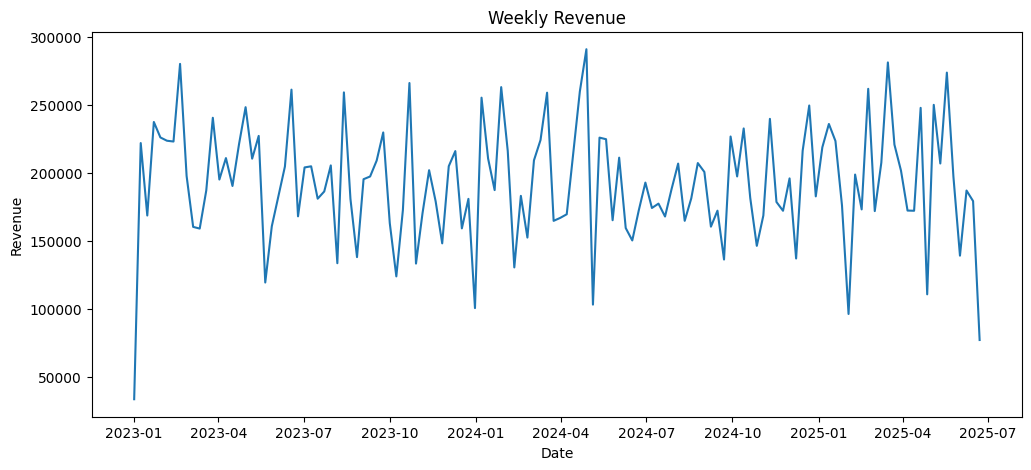

In [82]:
plt.figure(figsize=(12,5))

plt.plot(weekly['order_date'], weekly['revenue'])

plt.title("Weekly Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")

plt.show()

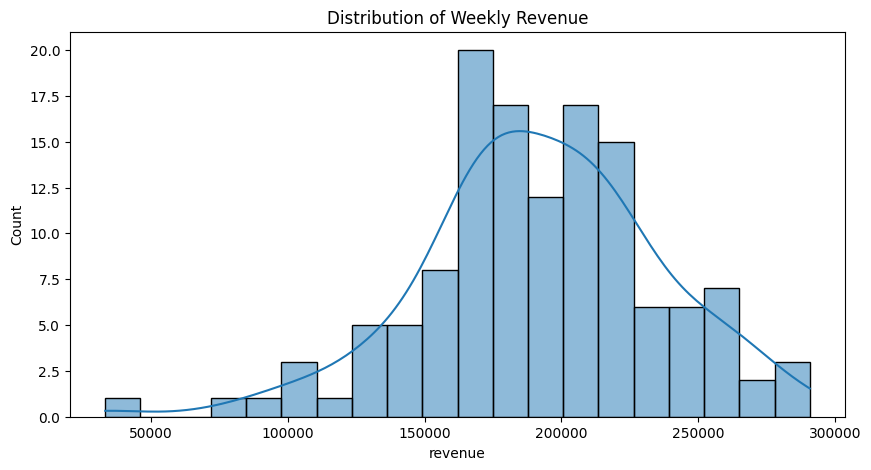

In [83]:
plt.figure(figsize=(10,5))

sns.histplot(weekly['revenue'], bins=20, kde=True)

plt.title("Distribution of Weekly Revenue")

plt.show()

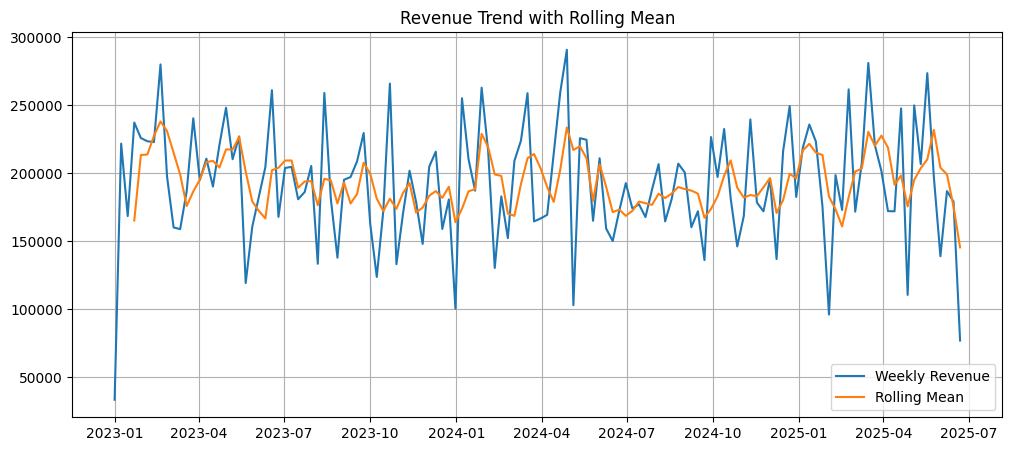

In [84]:
weekly['rolling_mean']=weekly['revenue'].rolling(4).mean()

plt.figure(figsize=(12,5))

plt.plot(weekly['order_date'], weekly['revenue'],label='Weekly Revenue')
plt.plot(weekly['order_date'], weekly['rolling_mean'], label='Rolling Mean')

plt.title('Revenue Trend with Rolling Mean')

plt.legend()
plt.grid()

plt.show()

## **Train Test Split**

In [85]:
train_size=int(len(weekly)*0.8)

train=weekly.iloc[:train_size]
test=weekly.iloc[train_size:]

print("Train:",len(train))
print("Test:",len(test))

Train: 104
Test: 26


## **Uji Stationeritas**

In [86]:
result=adfuller(train['revenue'])

print("\nADF:",result[0])
print("P-value:",result[1])


ADF: -3.864798196982896
P-value: 0.002309741175754178


In [87]:
if result[1]<0.05:
    print("Data Stasioner")
else:
    print("Belum Stasioner")

Data Stasioner


## **ACF dan PACF**

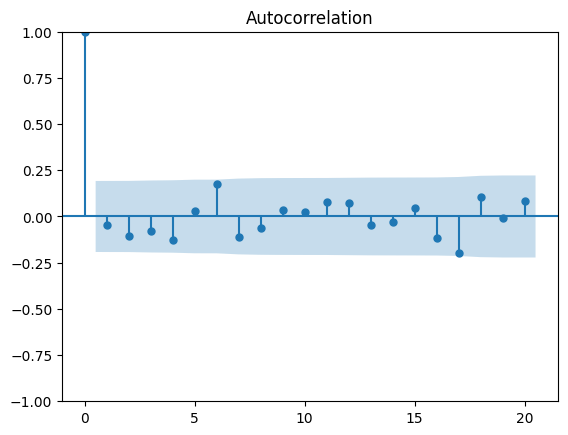

In [88]:
plot_acf(train['revenue'],lags=20)

plt.show()

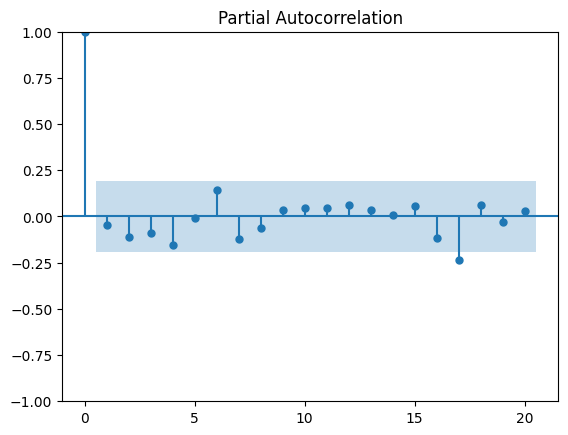

In [89]:
plot_pacf(train['revenue'],lags=20)

plt.show()


## **Pemodelan ARIMA**

In [90]:
models=[

(0,0,0),
(1,0,0),
(0,0,1),
(1,0,1),
(2,0,1),
(1,0,2),
(2,0,2)

]

hasil=[]
print("Perbandingan Model")

for i in models:
    model=ARIMA(train['revenue'], order=i)
    fit=model.fit()
    hasil.append([i,fit.aic])

    print(f"ARIMA{i}")
    print("AIC:", fit.aic)

aic=pd.DataFrame(hasil, columns=['Model','AIC'])
print(aic.sort_values('AIC'))

Perbandingan Model
ARIMA(0, 0, 0)
AIC: 2890.1904551321445
ARIMA(1, 0, 0)
AIC: 2513.0236265616436
ARIMA(0, 0, 1)
AIC: 2512.7876869155925
ARIMA(1, 0, 1)
AIC: 2512.303304912183
ARIMA(2, 0, 1)
AIC: 2513.419959627974
ARIMA(1, 0, 2)
AIC: 2514.5724394080216
ARIMA(2, 0, 2)
AIC: 2514.0347860403895
       Model          AIC
3  (1, 0, 1)  2512.303305
2  (0, 0, 1)  2512.787687
1  (1, 0, 0)  2513.023627
4  (2, 0, 1)  2513.419960
6  (2, 0, 2)  2514.034786
5  (1, 0, 2)  2514.572439
0  (0, 0, 0)  2890.190455


In [91]:
best=ARIMA(
train['revenue'],
order=(1,0,1)
)

fit=best.fit()

print(
fit.summary()
)

                               SARIMAX Results                                
Dep. Variable:                revenue   No. Observations:                  104
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -1252.152
Date:                Mon, 01 Jun 2026   AIC                           2512.303
Time:                        15:14:11   BIC                           2522.881
Sample:                             0   HQIC                          2516.589
                                - 104                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.916e+05   2608.360     73.448      0.000    1.86e+05    1.97e+05
ar.L1          0.6139      0.352      1.746      0.081      -0.075       1.303
ma.L1         -0.7438      0.304     -2.443      0.0

## **Forecasting**

In [92]:
forecast=fit.forecast(steps=len(test))

hasil=pd.DataFrame({
    'Actual': test['revenue'].values,
    'Forecast': forecast.values
})

hasil.head()

,Actual,Forecast
0,182497.47,186377.418133
1,218599.28,188385.898727
2,235749.21,189618.987137
3,223239.90,190376.030562
4,175793.37,190840.810494


## **Evaluasi Model**

In [93]:
mae=mean_absolute_error(test['revenue'], forecast)
rmse=np.sqrt(mean_squared_error(test['revenue'], forecast))
mape=mean_absolute_percentage_error(test['revenue'],forecast)

print("MAE:",mae)
print("RMSE:",rmse)
print("MAPE:",mape)
print("MAPE:", round(mape*100,2),"%")

MAE: 38649.69189914227
RMSE: 50108.355133869496
MAPE: 0.24887047076193466
MAPE: 24.89 %


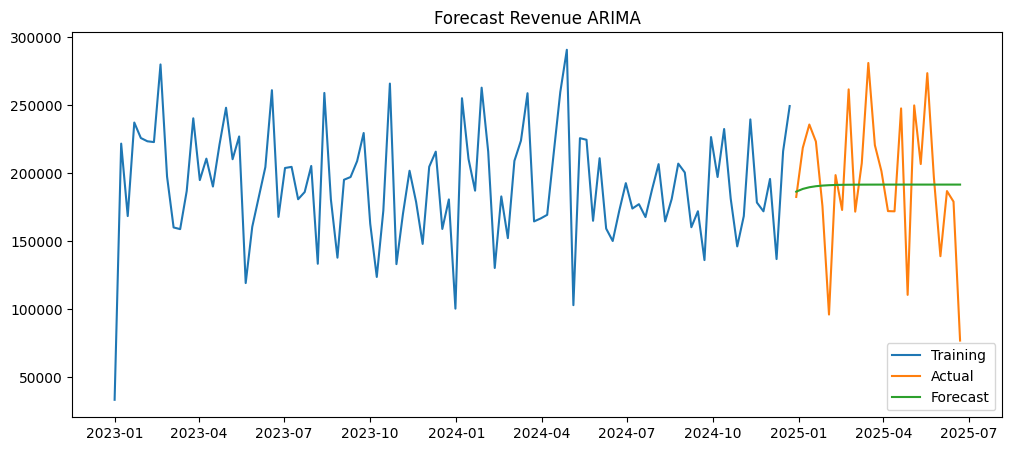

In [94]:
plt.figure(figsize=(12,5))

plt.plot(train['order_date'], train['revenue'], label='Training')
plt.plot(test['order_date'], test['revenue'],label='Actual')
plt.plot(test['order_date'], forecast, label='Forecast')

plt.title('Forecast Revenue ARIMA')

plt.legend()
plt.show()


## **Actual Forecast**

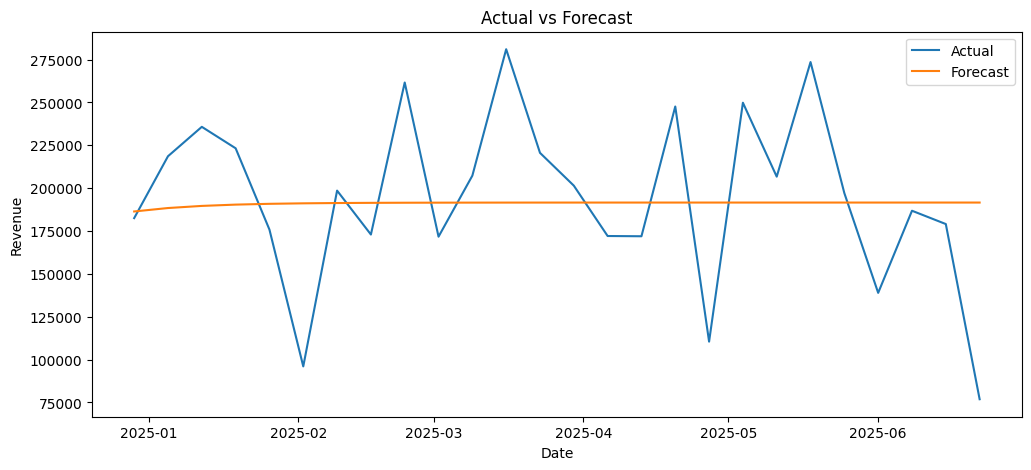

In [95]:
plt.figure(figsize=(12,5))

plt.plot(
test['order_date'],
test['revenue'],
label='Actual'
)

plt.plot(
test['order_date'],
forecast,
label='Forecast'
)

plt.title('Actual vs Forecast')
plt.xlabel('Date')
plt.ylabel('Revenue')

plt.legend()
plt.show()

## **Residual Diagnostic**

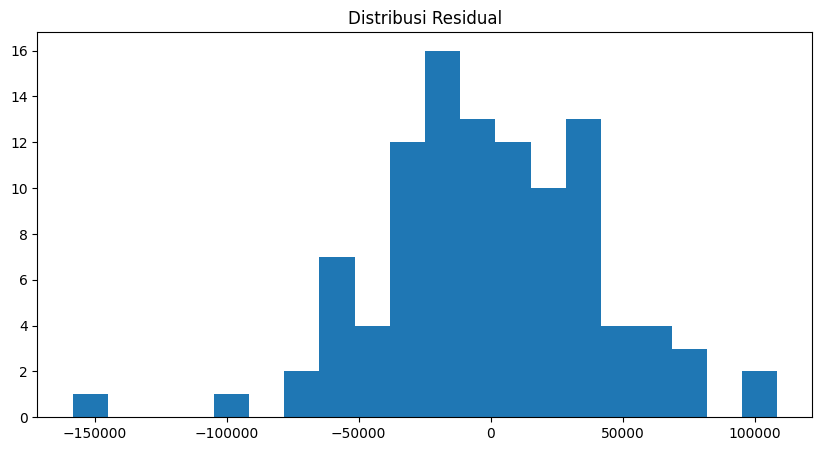

In [96]:
residual=fit.resid

plt.figure(figsize=(10,5))

plt.hist(residual, bins=20)

plt.title('Distribusi Residual')

plt.show()

## **Ljung Box**

In [97]:
lb=acorr_ljungbox(residual, lags=[10],return_df=True)

print("Ljung Box Test")
lb.head()

Ljung Box Test


,lb_stat,lb_pvalue
10,6.94112,0.730992


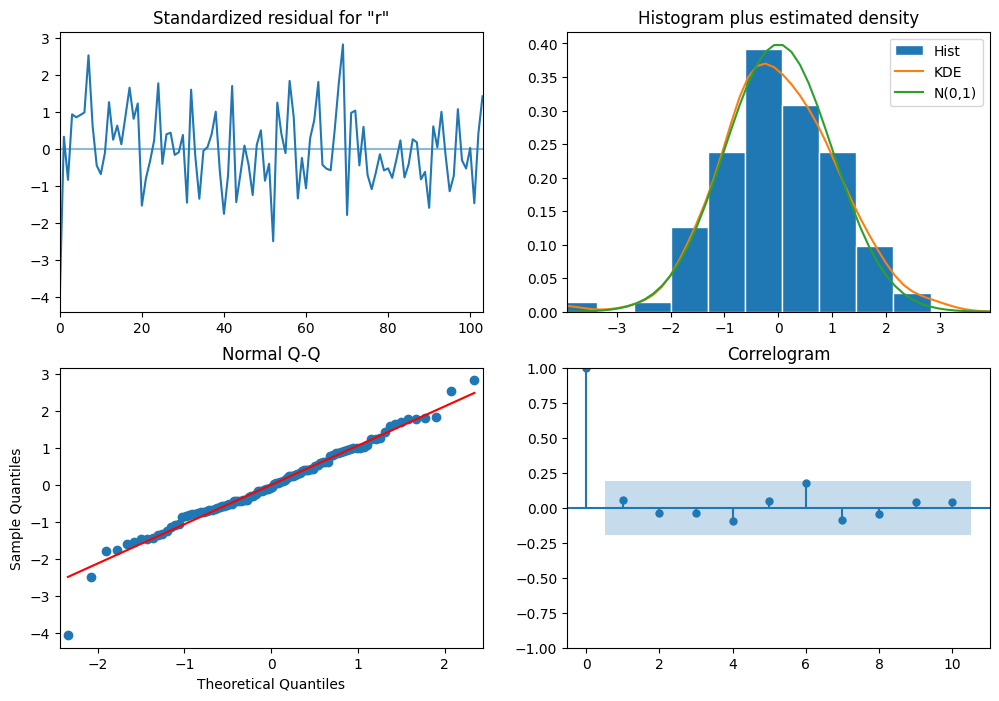

In [98]:
fit.plot_diagnostics(figsize=(12,8))

plt.show()

## **Future Forecast**

In [101]:
final_model=ARIMA(
weekly['revenue'],
order=(1,0,1)
)

final_fit=final_model.fit()

future_date=pd.date_range(
start=weekly['order_date'].iloc[-1],
periods=13,
freq='W'
)[1:]

future=final_fit.forecast(12)

future_df=pd.DataFrame({
'Date':future_date,
'Forecast':future.values
})

future_df.reset_index(drop=True,inplace=True)

future_df

,Date,Forecast
0,2025-06-29,193456.216290
1,2025-07-06,193271.818935
2,2025-07-13,193108.099111
3,2025-07-20,192962.738131
4,2025-07-27,192833.677310
5,2025-08-03,192719.088819
6,2025-08-10,192617.349793
7,2025-08-17,192527.019347
8,2025-08-24,192446.818171
9,2025-08-31,192375.610413
